# Projet 7 – Étape 1 : Exploration du dataset

**Dataset :** IRM cérébrales pour détection de tumeurs  
**Structure :**
- `avec_labels/cancer/` → 50 images labelisées "cancer"
- `avec_labels/normal/` → 50 images labelisées "normal"
- `sans_label/` → ~1406 images non labelisées

**Objectif de cette étape :** comprendre ce qu'on a avant de faire quoi que ce soit.

## 0. Imports et configuration

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from jbtools import describoost

# Adapte ce chemin à ton orga
ROOT = Path(".")

DIR_CANCER  = ROOT / "avec_labels_old" / "cancer"
DIR_NORMAL  = ROOT / "avec_labels_old" / "normal"
DIR_UNLABEL = ROOT / "sans_label_old"

print("Dossiers trouvés :")
for d in [DIR_CANCER, DIR_NORMAL, DIR_UNLABEL]:
    print(f"  {d.name} → existe : {d.exists()}")

Dossiers trouvés :
  cancer → existe : True
  normal → existe : True
  sans_label_old → existe : True


## 1. Comptage et inventaire

In [2]:
def lister_images(dossier):
    """Retourne la liste des fichiers .jpg dans un dossier."""
    return sorted(dossier.glob("*.jpg"))

images_cancer  = lister_images(DIR_CANCER)
images_normal  = lister_images(DIR_NORMAL)
images_unlabel = lister_images(DIR_UNLABEL)

print(f"Cancer   (labelisé) : {len(images_cancer)} images")
print(f"Normal   (labelisé) : {len(images_normal)} images")
print(f"Sans label          : {len(images_unlabel)} images")
print(f"Total               : {len(images_cancer) + len(images_normal) + len(images_unlabel)} images")

Cancer   (labelisé) : 50 images
Normal   (labelisé) : 50 images
Sans label          : 1406 images
Total               : 1506 images


## 2. Vérification des tailles et canaux

Le dataset annonce des images 512×512. On vérifie sur un échantillon que c'est bien le cas,
et on regarde si les images sont en niveaux de gris (1 canal) ou RGB (3 canaux).

In [3]:
def inspecter_echantillon(liste_images, label, n=10):
    """
    Ouvre les n premières images et récupère taille + mode couleur.
    Retourne un DataFrame récapitulatif.
    """
    infos = []
    for img_path in liste_images[:n]:
        with Image.open(img_path) as img:
            infos.append({
                "label"    : label,
                "fichier"  : img_path.name,
                "largeur"  : img.size[0],
                "hauteur"  : img.size[1],
                "mode"     : img.mode,   # L = gris, RGB = couleur
                "taille_ko": round(img_path.stat().st_size / 1024, 1)
            })
    return pd.DataFrame(infos)

df_cancer  = inspecter_echantillon(images_cancer,  "cancer",  n=50)
df_normal  = inspecter_echantillon(images_normal,  "normal",  n=50)
df_unlabel = inspecter_echantillon(images_unlabel, "sans_label", n=2000)

df_inspection = pd.concat([df_cancer, df_normal, df_unlabel], ignore_index=True)
# print(df_inspection.to_string(index=False))

print(df_cancer.head(10).to_string(index=False))
print()
print(df_normal.head(10).to_string(index=False))
print()
print(df_unlabel.head(10).to_string(index=False))
print()

 label                                  fichier  largeur  hauteur mode  taille_ko
cancer 05340cd4-3bb2-459d-9937-bf27d52d8351.jpg      512      512  RGB       25.2
cancer 0c6f3641-60d9-4a76-abe5-de89d55d5f2c.jpg      512      512  RGB       17.7
cancer 0f718241-8f63-4b55-81ce-315324b51069.jpg      512      512  RGB       17.7
cancer 11a7a426-4806-401e-98b2-b96e7094d1a6.jpg      512      512  RGB       24.0
cancer 1c043dbb-4623-4769-8e5e-0223bd745040.jpg      512      512  RGB       24.1
cancer 27149ff6-8363-4942-a72a-eb7e38e77099.jpg      512      512  RGB       28.5
cancer 2b810835-844c-49ff-b0f1-c7a71a0c696c.jpg      512      512  RGB       22.4
cancer 2d662cc1-509b-4657-a208-6d181aedd5e3.jpg      512      512  RGB       16.7
cancer 2fa551e9-5b85-44f6-ab71-6035b4e3f8aa.jpg      512      512  RGB       31.8
cancer 3c3d07cb-ec2a-43b0-b8a3-3a51573ad930.jpg      512      512  RGB       18.8

 label                                  fichier  largeur  hauteur mode  taille_ko
normal 0161f9bf

In [4]:
# Résumé : est-ce que toutes les images ont bien la même taille et le même mode ?
print("Tailles distinctes trouvées :")
print(df_inspection.groupby(["largeur", "hauteur", "mode"]).size().reset_index(name="count"))

Tailles distinctes trouvées :
   largeur  hauteur mode  count
0      512      512  RGB   1506


In [5]:
describoost(df_normal,"Normal")
describoost(df_cancer,"Cancer")
describoost(df_unlabel,"Unlabeled")



==================== 🚀 DESCRIBOOST : Normal ====================
Nbre de lignes  : 50 
Nbre de colonnes: 6 

--- ANALYSE NUMÉRIQUE ---
           count   mean   std    min    25%    50%    75%    max  skewsc  mean/md Minidist  NaNs  Nan%       Remarque   Suggestion
taille_ko  50.00  29.13 11.36  17.40  23.00  25.30  29.38  64.30    4.00     1.20     ███_  0.00  0.00   R-outlier(s)  log?/suppr?
largeur    50.00 512.00  0.00 512.00 512.00 512.00 512.00 512.00    0.00     1.00     ----  0.00  0.00  Valeur Unique  A supprimer
hauteur    50.00 512.00  0.00 512.00 512.00 512.00 512.00 512.00    0.00     1.00     ----  0.00  0.00  Valeur Unique  A supprimer

--- ANALYSE CATEGORIELLE ---
        count unique                                       top freq  freq%  cat.mean  cat.tp/mean  NaNs  Nan%           Remarque   Suggestion
label      50      1                                    normal   50 100.00     50.00         1.00     0  0.00      Valeur Unique  A supprimer
mode       50      1      

## 3. Visualisation d'exemples

On affiche quelques images de chaque catégorie pour voir à quoi ressemble le dataset.

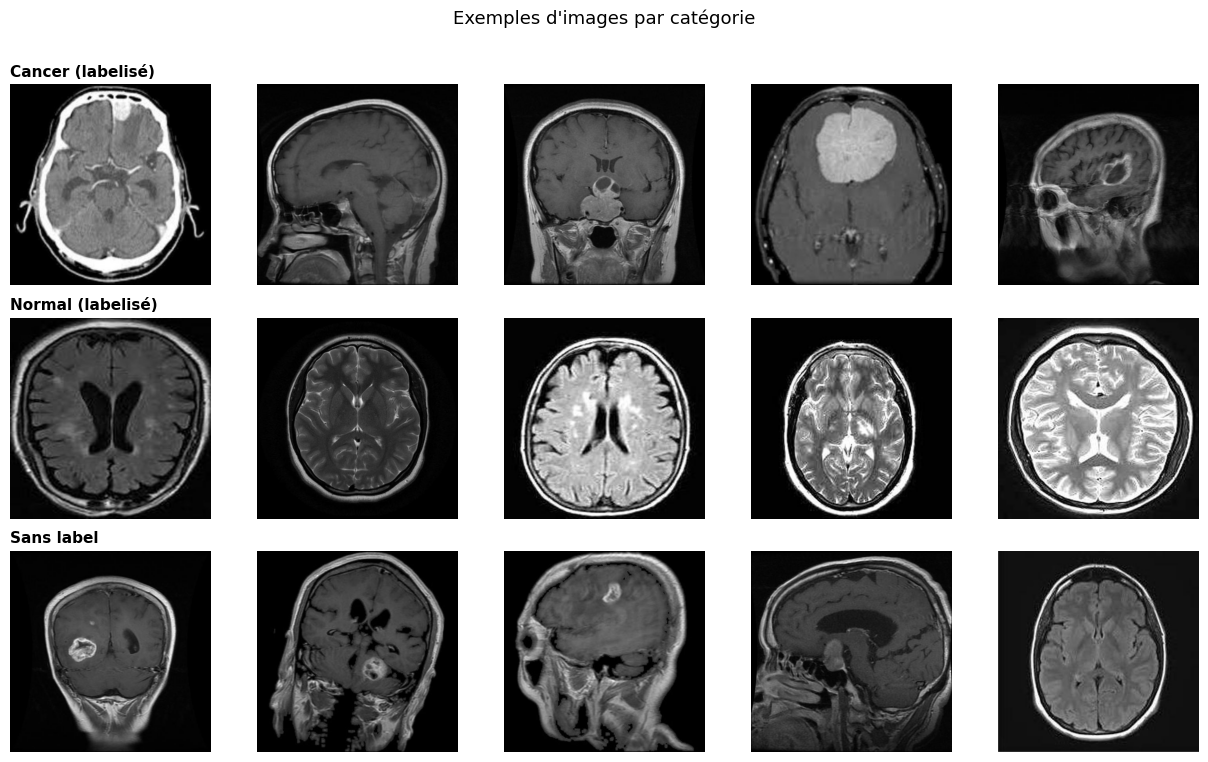

In [6]:
def afficher_grille(listes_et_labels, n_par_classe=5):
    """
    Affiche une grille d'images : une ligne par classe.
    listes_et_labels = [(liste_chemins, "nom_classe"), ...]
    """
    n_classes = len(listes_et_labels)
    fig, axes = plt.subplots(n_classes, n_par_classe, figsize=(n_par_classe * 2.5, n_classes * 2.5))
    
    for row, (liste, label) in enumerate(listes_et_labels):
        for col in range(22,22+n_par_classe):
            ax = axes[row][col-22]
            with Image.open(liste[col]) as img:
                ax.imshow(img, cmap="gray" if img.mode == "L" else None)
            ax.axis("off")
            if col == 22:
                ax.set_title(label, fontsize=11, fontweight="bold", loc="left")
    
    plt.suptitle("Exemples d'images par catégorie", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

afficher_grille([
    (images_cancer,  "Cancer (labelisé)"),
    (images_normal,  "Normal (labelisé)"),
    (images_unlabel, "Sans label"),
], n_par_classe=5)

## 4. Distribution des tailles de fichiers

Un gros écart de taille de fichier peut indiquer des images de qualité très variable.

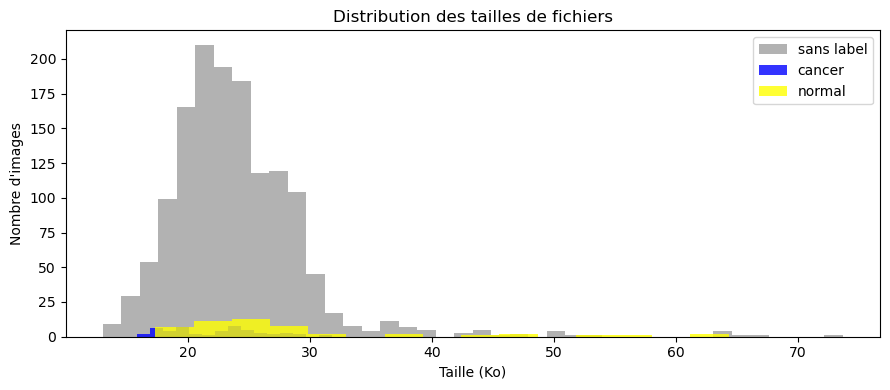

Sans label — min: 13 Ko | max: 74 Ko | moy: 24 Ko
Cancer     — min: 16 Ko | max: 32 Ko | moy: 22 Ko
Normal     — min: 17 Ko | max: 64 Ko | moy: 29 Ko


In [7]:
def tailles_fichiers(liste_images):
    return [img_path.stat().st_size / 1024 for img_path in liste_images]

tailles_cancer  = tailles_fichiers(images_cancer)
tailles_normal  = tailles_fichiers(images_normal)
tailles_unlabel = tailles_fichiers(images_unlabel)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(tailles_unlabel, bins=40, alpha=0.6, label="sans label", color="grey")
ax.hist(tailles_cancer,  bins=15, alpha=0.8, label="cancer",     color="blue")
ax.hist(tailles_normal,  bins=15, alpha=0.8, label="normal",     color="yellow")
ax.set_xlabel("Taille (Ko)")
ax.set_ylabel("Nombre d'images")
ax.set_title("Distribution des tailles de fichiers")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Sans label — min: {min(tailles_unlabel):.0f} Ko | max: {max(tailles_unlabel):.0f} Ko | moy: {np.mean(tailles_unlabel):.0f} Ko")
print(f"Cancer     — min: {min(tailles_cancer):.0f} Ko | max: {max(tailles_cancer):.0f} Ko | moy: {np.mean(tailles_cancer):.0f} Ko")
print(f"Normal     — min: {min(tailles_normal):.0f} Ko | max: {max(tailles_normal):.0f} Ko | moy: {np.mean(tailles_normal):.0f} Ko")

## 5. Bilan et observations

| Élément | Observation |
|---|---|
| Nombre d'images | 100 labelisées (50+50) / 1406 sans label |
| Résolution | 512×512 px |
| Mode couleur | RGB = couleur (pas de convertion necessaire)|
| Qualité visuelle | Bonne qualité sauf quelques exceptions |
| Déséquilibre des classes | Aucun : 50/50 sur les données labelisées |


## 6. Egalisation d'histogramme - Amelioration du contraste (OpenCV)

In [8]:
import cv2

# Définition des chemins (source et cible)

DIR_CANCER   = ROOT / "avec_labels_old" / "cancer"
DIR_NORMAL   = ROOT / "avec_labels_old" / "normal"
DIR_UNLABEL  = ROOT / "sans_label_old"

DIR_CANCER_HEQ  = ROOT / "avec_labels" / "cancer"
DIR_NORMAL_HEQ  = ROOT / "avec_labels" / "normal"
DIR_UNLABEL_HEQ = ROOT / "sans_label"

# Configuration de CLAHE - config de référence pour optimiser le contraste des tissus sans amplifier le bruit de fond de l'appareil d'IRM
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

# Association des dossiers sources et destinations pour la boucle
mappings = [
    (DIR_CANCER, DIR_CANCER_HEQ),
    (DIR_NORMAL, DIR_NORMAL_HEQ),
    (DIR_UNLABEL, DIR_UNLABEL_HEQ)
]

# Boucle de traitement
for src_dir, dest_dir in mappings:
    print(f"Traitement de : {src_dir}...")
    
    dest_dir.mkdir(parents=True, exist_ok=True)     # Créer le dossier de destination s'il n'existe pas
            
    for img_path in src_dir.glob('*.jpg'):
        img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)   # Lire en niveaux de gris
        
        if img is not None:
            img_heq = clahe.apply(img)                          # Appliquer CLAHE
            img_rgb = cv2.cvtColor(img_heq, cv2.COLOR_GRAY2RGB) # Reconvertir en 3 canaux (Gris -> RGB) pour ResNet50
            dest_path = dest_dir / img_path.name                # Sauvegarder dans le nouveau dossier avec le même nom
            cv2.imwrite(str(dest_path), img_rgb)
        else:
            print(f"Erreur de lecture sur l'image : {img_path.name}")

print("\n=== BILAN DU TRAITEMENT ===")
for src_dir, dest_dir in mappings:
    src_final_count = len(list(src_dir.glob('*.jpg')))
    dest_final_count = len(list(dest_dir.glob('*.jpg')))
    print(f"Dossier {src_dir} : {src_final_count} sources => {dest_final_count} cibles créées dans '{dest_dir}'")
print("===========================")

Traitement de : avec_labels_old\cancer...
Traitement de : avec_labels_old\normal...
Traitement de : sans_label_old...

=== BILAN DU TRAITEMENT ===
Dossier avec_labels_old\cancer : 50 sources => 50 cibles créées dans 'avec_labels\cancer'
Dossier avec_labels_old\normal : 50 sources => 50 cibles créées dans 'avec_labels\normal'
Dossier sans_label_old : 1406 sources => 1406 cibles créées dans 'sans_label'
